# Appendix – analysis details (NOT FOR SUBMISSION)

Working material behind `Assignment3_LKF.ipynb` and `Assignment3_extensions.ipynb`, kept for reference: comparison of calibration forms (Sharp, quadratic, cubic; S-only vs final), the synthetic wall-approach simulation, leave-one-run-out with the S-only calibration, the $k$ and $\sigma_\text{cal}$ scans, the electrical regression of the motor, and per-channel NIS of the extension filters. Section titles follow the earlier single notebook.

In [1]:
# Load everything from the main and the extensions notebook (their code cells, without output)
import nbformat, io, contextlib, warnings, matplotlib.pyplot as plt
_show_appendix = plt.show; plt.show = lambda *a, **k: None
try:
    with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for _c in nbformat.read('Assignment3_extensions.ipynb', 4).cells:
            if _c.cell_type == 'code':
                exec(_c.source)
finally:
    plt.show = _show_appendix; plt.close('all')
from scipy.optimize import curve_fit
from scipy.stats import norm, chi2

### 2.2 Measurement model: calibration of the front sensor

Six static recordings, robot square to a flat wall at a tape-measured distance $d$ from its **front edge** (`S_50mm` … `S_300mm`, motors off). `getFrontDistance()` returns $m$ from the library curve $m = 24.7694/\text{raw} + 0.0109$ (`sharp41S.cpp`), so the ADC value can be recovered exactly: $\text{raw} = 24.7694/(m-0.0109)$ (whole counts).

The library curve does not fit this sensor: the bias grows from +17 mm to +71 mm. A filter cannot remove that: it is **systematic**, not noise ($Q$ and $R$ only describe random errors), so the readings are calibrated *before* the correction step. First, two forms are compared on the six S points:

* (a) Sharp form $d = a/(\text{raw}+k) + b$;
* (b) quadratic in $m$: $d = c_2 m^2 + c_1 m + c_0$.

The calibration maps to the tape distance from the robot's front edge, so it also absorbs the **mounting offset** of the sensor (its face is 10 mm behind the edge). It is only valid in **42–300 mm**, where there is data (S recordings and the standstill points of the drives, 2.2b). $\mathbf H = -R_\text{wheel}$ stays linear: the calibration acts on the reading, not on the state.

 tape [mm]  library m [mm]  bias [mm]  std m [mm]  std raw [counts]  resid (a) [mm]  resid (b) [mm]  noise after cal. [mm]  LOO (a) [mm]  LOO (b) [mm]
      50.0           68.12      18.12        0.25              1.87           -0.91           -0.63                   0.26         -5.18         -2.68
     100.0          117.27      17.27        0.26              0.56            0.76            0.17                   0.25          1.10          0.24
     150.0          170.96      20.96        0.95              0.93            1.56            1.25                   0.87          2.43          1.84
     200.0          228.18      28.18        0.97              0.51            0.17            0.62                   0.79          0.26          1.02
     250.0          289.43      39.43        2.16              0.68           -3.18           -2.33                   1.55         -4.57         -3.51
     300.0          370.87      70.87        5.07              1.00            1.60           

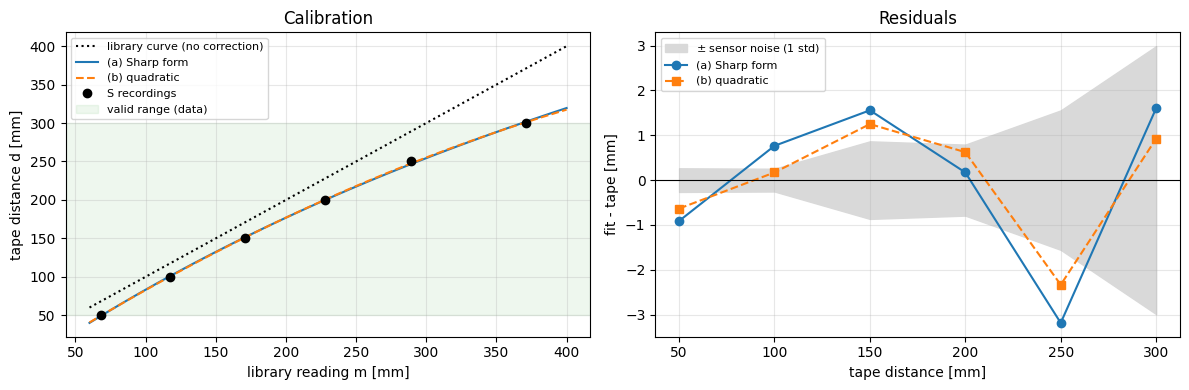

In [2]:
SHARP_A, SHARP_B = 24.7694, 0.0109311               # library curve (sharp41S.cpp): m = SHARP_A / raw + SHARP_B
TAPE_MM = [50, 100, 150, 200, 250, 300]             # data/A3/S_<d>mm.csv

rows = []
for d in TAPE_MM:
    m = load_log(DATA_A3 / f'S_{d}mm.csv', firmware='identification_a3').front.values
    raw = SHARP_A / (m - SHARP_B)                   # ADC counts
    rows.append(dict(tape=d / 1e3, m=m.mean(), m_std=m.std(), raw=raw.mean(), raw_std=raw.std(), n=len(m),
                     whole_counts=np.allclose(raw, np.round(raw), atol=1e-2), dropouts=int((m > 1).sum())))
stat = pd.DataFrame(rows)

# (a) Sharp form on the recovered ADC value, (b) quadratic in m
sharp = lambda raw, a, k, b: a / (raw + k) + b
p_sharp, _ = curve_fit(sharp, stat.raw, stat.tape, p0=[SHARP_A, 0, 0])
CAL_S = tuple(np.polyfit(stat.m, stat.tape, 2))                     # quadratic on the S points only (compared in 2.2b)
CAL_C2, CAL_C1, CAL_C0 = CAL_S
calibrate = lambda m: (CAL_C2 * m + CAL_C1) * m + CAL_C0          # the firmware evaluates it the same way
dd_dm = lambda m: 2 * CAL_C2 * m + CAL_C1                          # slope of the calibration

def loo(fit_predict):
    # leave-one-out: fit on 5 points, predict the 6th
    out = []
    for i in range(len(stat)):
        k = np.arange(len(stat)) != i
        out.append(fit_predict(stat[k], stat.iloc[i]))
    return np.array(out)
loo_a = loo(lambda s, r: sharp(r.raw, *curve_fit(sharp, s.raw, s.tape, p0=[SHARP_A, 0, 0], maxfev=20000)[0]))
loo_b = loo(lambda s, r: np.polyval(np.polyfit(s.m, s.tape, 2), r.m))

tab = pd.DataFrame({
    'tape [mm]': 1e3 * stat.tape, 'library m [mm]': 1e3 * stat.m, 'bias [mm]': 1e3 * (stat.m - stat.tape),
    'std m [mm]': 1e3 * stat.m_std, 'std raw [counts]': stat.raw_std,
    'resid (a) [mm]': 1e3 * (sharp(stat.raw, *p_sharp) - stat.tape), 'resid (b) [mm]': 1e3 * (calibrate(stat.m) - stat.tape),
    'noise after cal. [mm]': 1e3 * dd_dm(stat.m) * stat.m_std,
    'LOO (a) [mm]': 1e3 * (loo_a - stat.tape), 'LOO (b) [mm]': 1e3 * (loo_b - stat.tape)})
print(tab.round(2).to_string(index=False))
print(f"\nwhole ADC counts in every file: {stat.whole_counts.all()};  drop-outs: {stat.dropouts.sum()}")
for name, col, lcol in [('(a) Sharp form', 'resid (a) [mm]', 'LOO (a) [mm]'), ('(b) quadratic ', 'resid (b) [mm]', 'LOO (b) [mm]')]:
    print(f'{name}: residual rms {np.sqrt(np.mean(tab[col]**2)):.2f} mm, leave-one-out rms {np.sqrt(np.mean(tab[lcol]**2)):.2f} mm')
print(f'-> quadratic on the S points: d = {CAL_C2:.6f} m^2 + {CAL_C1:.6f} m + {CAL_C0:.6f}  [m]')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mm = np.linspace(0.06, 0.40, 300)
ax[0].plot(1e3 * mm, 1e3 * mm, 'k:', label='library curve (no correction)')
ax[0].plot(1e3 * mm, 1e3 * sharp(SHARP_A / (mm - SHARP_B), *p_sharp), label='(a) Sharp form')
ax[0].plot(1e3 * mm, 1e3 * calibrate(mm), '--', label='(b) quadratic')
ax[0].plot(1e3 * stat.m, 1e3 * stat.tape, 'ko', label='S recordings')
ax[0].axhspan(50, 300, color='tab:green', alpha=0.08, label='valid range (data)')
ax[0].set(xlabel='library reading m [mm]', ylabel='tape distance d [mm]', title='Calibration'); ax[0].legend(fontsize=8)
noise = tab['noise after cal. [mm]']
ax[1].fill_between(tab['tape [mm]'], -noise, noise, color='0.85', label=r'$\pm$ sensor noise (1 std)')
ax[1].plot(tab['tape [mm]'], tab['resid (a) [mm]'], 'o-', label='(a) Sharp form')
ax[1].plot(tab['tape [mm]'], tab['resid (b) [mm]'], 's--', label='(b) quadratic')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set(xlabel='tape distance [mm]', ylabel='fit - tape [mm]', title='Residuals'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Choice: (b) quadratic.** It has the smaller residuals (fit and leave-one-out), and it costs two multiplications on the Arduino. The residuals (rms 1.2 mm, max 2.3 mm) are larger than the sensor noise at some distances, but each point is the mean of thousands of samples, so its own noise is negligible: the residuals show how exactly the robot was placed at the tape mark, and they are consistent with a ruler/placement uncertainty of 3–5 mm. A better fit than that is not possible with this data. Leaving out the 300 mm point gives the largest error, so the curve must not be used outside the range of the data.

### 2.2b Calibration in the drive set-up

At the edge of its range (30 cm) the sensor reading depends on the set-up: at the same 300 mm tape mark, S_300 and the starts of the drives W1–W3 are about 4 ADC counts apart (raw 0.371 m vs 0.351–0.356 m). That is why the final calibration also uses points recorded **in the drive set-up**: the standstill before each drive (300 mm) and after it (42–45 mm), tape-measured. Each standstill window counts once (its mean), so the fit uses 12 points: 6 S + 6 W. Closed-loop distance targets are kept at **100–200 mm**, away from the edge of the range.

The quadratic form is kept: a cubic does not reduce the residuals. The end points of W1–W3 are now part of the fit, so the replay in section 5 is in-sample for the end error; the honest check is the leave-one-run-out in section 5.0.

Residuals (fit - tape):
  source  tape [mm]  library m [mm]  S-only fit [mm]  final fit [mm]  cubic [mm]
       S       50.0            68.1             -0.6            -5.8        -5.6
       S      100.0           117.3              0.2            -2.9        -3.6
       S      150.0           171.0              1.2             0.5        -0.1
       S      200.0           228.2              0.6             2.2         2.4
       S      250.0           289.4             -2.3             1.7         2.5
       S      300.0           370.9              0.9             8.1         7.5
W1 start      300.0           355.8             -8.2            -1.6        -1.6
  W1 end       44.0            70.1              7.5             2.4         2.5
W2 start      300.0           351.2            -11.0            -4.6        -4.5
  W2 end       45.0            69.3              5.6             0.5         0.6
W3 start      300.0           351.0            -11.1            -4.7        -4.6
  W3

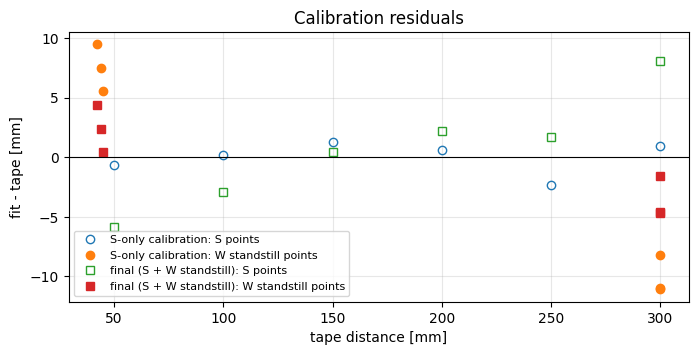

In [3]:
def load_w(path):
    mt = re.match(r'W(\d+)_start(\d+)_end(\d+)', path.stem)
    df = load_log(path, firmware='identification_a3')
    w = ((df.wA + df.wB) / 2).values
    mv = np.flatnonzero(np.abs(w) > 0)
    return dict(name=path.stem, t=df.t.values, m=df.front.values, w=w, d_start=int(mt[2]) / 1e3, d_end=int(mt[3]) / 1e3,
                drive=slice(mv[0], mv[-1] + 30))                            # wheels turning + 0.3 s

def standstill(r):
    # (start, end) windows: before the drive and from 1 s after the wheels stop
    t0 = r['t'][r['drive']][0]; t_stop = r['t'][np.flatnonzero(np.abs(r['w']) > 0)[-1]]
    return (r['t'] > 0.5) & (r['t'] < t0 - 0.2), r['t'] > t_stop + 1.0

WRUNS = [load_w(p) for p in sorted(DATA_A3.glob('W*_start*_end*.csv'))]

pts = [dict(source='S', tape=r.tape, m=r.m) for r in stat.itertuples()]
for r in WRUNS:
    sel_start, sel_end = standstill(r)
    pts.append(dict(source=r['name'][:2] + ' start', tape=r['d_start'], m=r['m'][sel_start].mean()))
    pts.append(dict(source=r['name'][:2] + ' end', tape=r['d_end'], m=r['m'][sel_end].mean()))
cal_pts = pd.DataFrame(pts)

def fit_cal(points):
    return tuple(np.polyfit(points.m, points.tape, 2))

def use_cal(c):
    # set the calibration used by calibrate(), dd_dm(), R(d) and lkf()
    global CAL_C2, CAL_C1, CAL_C0
    CAL_C2, CAL_C1, CAL_C0 = c

CAL_ALL = fit_cal(cal_pts)
use_cal(CAL_ALL)
cubic = np.polyfit(cal_pts.m, cal_pts.tape, 3)
show = pd.DataFrame({'source': cal_pts.source, 'tape [mm]': 1e3 * cal_pts.tape, 'library m [mm]': 1e3 * cal_pts.m,
                     'S-only fit [mm]': 1e3 * (np.polyval(CAL_S, cal_pts.m) - cal_pts.tape),
                     'final fit [mm]': 1e3 * (calibrate(cal_pts.m) - cal_pts.tape),
                     'cubic [mm]': 1e3 * (np.polyval(cubic, cal_pts.m) - cal_pts.tape)})
print('Residuals (fit - tape):'); print(show.round(1).to_string(index=False))
rms = lambda v: np.sqrt(np.mean(np.square(v)))
print(f"\nrms over all 12 points: S-only quadratic {rms(show['S-only fit [mm]']):.1f} mm, final quadratic {rms(show['final fit [mm]']):.1f} mm, cubic {rms(show['cubic [mm]']):.1f} mm")
print(f'-> final calibration: d = {CAL_C2:.6f} m^2 + {CAL_C1:.6f} m + {CAL_C0:.6f}  [m];  one-to-one up to m = {-CAL_C1/(2*CAL_C2):.3f} m')

plt.figure(figsize=(8, 3.5))
isS = cal_pts.source == 'S'
for col, mk, lab in [('S-only fit [mm]', 'o', 'S-only calibration'), ('final fit [mm]', 's', 'final (S + W standstill)')]:
    plt.plot(show['tape [mm]'][isS], show[col][isS], mk, mfc='none', label=f'{lab}: S points')
    plt.plot(show['tape [mm]'][~isS], show[col][~isS], mk, label=f'{lab}: W standstill points')
plt.axhline(0, color='k', lw=0.8); plt.xlabel('tape distance [mm]'); plt.ylabel('fit - tape [mm]')
plt.title('Calibration residuals'); plt.legend(fontsize=8); plt.show()

## 3. The filter and a simulated wall approach
Order as in `robot.cpp`: **correction** with the new measurement, then **prediction** to the next sample. An optional **gate**, identical to `CorrectionUpdate` in the firmware, calibrates every reading first and skips the update for drop-outs (24.78 m), NaN/inf and readings above 0.40 m (raw value: the calibration is fitted up to 0.371 m, and beyond 30 cm the sensor over-reads instead of dropping out), for **calibrated** distances outside 0.04–0.32 m (sensor range 0.04–0.30 m plus margin) and for innovations above 3σ ($\nu^2/S>9$). If more than 20 samples in a row (0.2 s) fail the 3σ test, the measurement is accepted again and $P$ is first widened to $P_\text{resync}=9.5$ rad² ($\approx$ 10 cm): then the *estimate* is wrong, not the sensor (e.g. a wrong initial guess), and a pure 3σ gate would lock the filter out forever. The counter starts at 0 for every run (`ResetGate()`).

The simulation drives from 0.30 m (the edge of the sensor range) to about 0.10 m (still, accelerate to 3 rad/s, cruise, brake), with a simulated sensor that works like the real one (true distance + a **calibration error** → ADC counts with $c$ counts of noise → whole counts → library curve). The calibration error is a smooth bias, drawn per run: values ~N(0, 2 mm) at 50, 100, … 300 mm, linearly interpolated, so each run has its own systematic error like a real calibration, 1.5 % drop-outs reading 24.78 m, the measured wheel-speed noise, and a **5 % wheel-speed scale error** that the filter does not know about. As on the robot, the filter starts from the **tape-measured start distance** (typed in ValueOut1), simulated with a ruler error of $\sigma_\text{ruler}=5$ mm (assumed), so $P_0=(\sigma_\text{ruler}/R_\text{wheel})^2$, the firmware value. Section 3.1 also starts from a *deliberately wrong* estimate to show the re-sync.

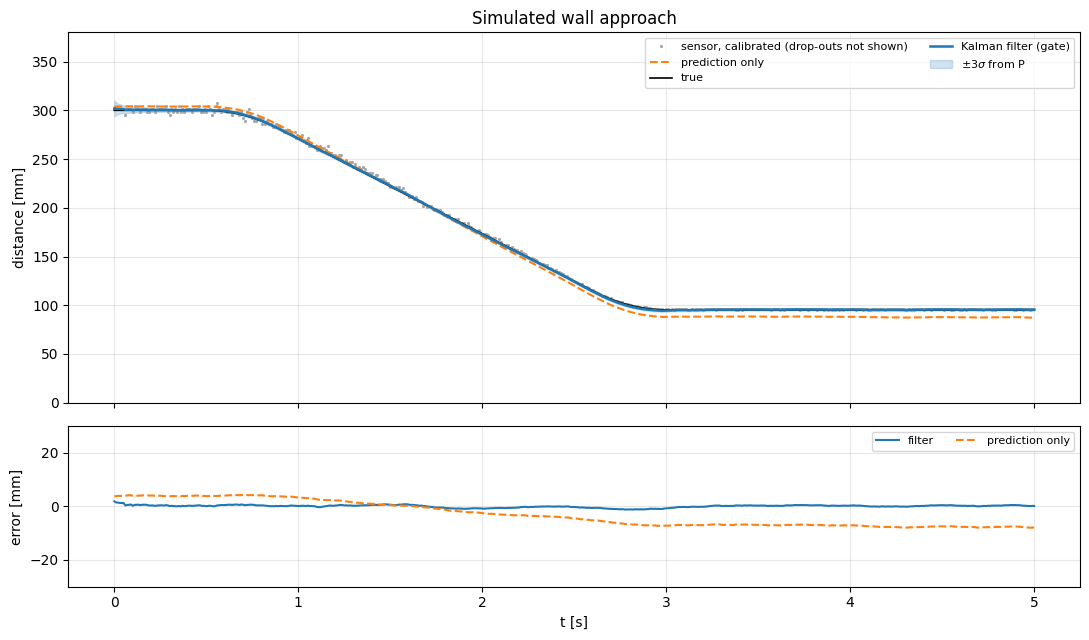

In [4]:
GATE, SIG_RULER, W_CRUISE = 9.0, 0.005, 3.0                                # ruler uncertainty of the start distance [m] (assumed)
M_RAW_MAX, D_MIN, D_MAX, MAX_REJECT = 0.40, 0.04, 0.32, 20                 # raw limit [m]; calibrated range [m]; re-sync after 0.2 s
P0_STATE = (SIG_RULER / R_WHEEL)**2                                        # [rad^2] = P0_STATE in state_estimator.h
P_RESYNC = 9.5                                                             # [rad^2] = P_RESYNC in state_estimator.h, ~(0.10 m / R_WHEEL)^2
P0 = P0_STATE
SIG_W_ENC = SIGMA_OMEGA                                                    # wheel-speed noise [rad/s] from section 2.1

m_grid = np.linspace(SHARP_B + 0.03, 0.70, 20000); d_grid = calibrate(m_grid)        # one-to-one up to 0.70 m; beyond 0.30 m the
# simulated sensor over-reads like the real one (m > M_RAW_MAX -> rejected by the gate)
CAL_KNOTS = np.array(TAPE_MM) / 1e3                                        # [m] where the calibration error is drawn
def sensor(d_true, rng, cal_bias):
    # library reading m for a true distance: + calibration error -> inverse calibration -> ADC counts + noise
    # -> whole counts -> library curve
    d_seen = d_true + np.interp(d_true, CAL_KNOTS, cal_bias)                # smooth systematic error of this run
    raw = SHARP_A / (np.interp(d_seen, d_grid, m_grid) - SHARP_B)
    raw = np.round(raw + rng.normal(0, np.sqrt(max(NOISE_C**2 - 1/12, 0)), len(raw)))   # rounding adds 1/12 count^2
    return SHARP_A / raw + SHARP_B

def simulate(seed, d0=0.30, T=5.0, eps=0.05, p_drop=0.015):
    rng = np.random.default_rng(seed); n = int(round(T/DT)) + 1; tt = np.arange(n) * DT
    w_true = np.interp(tt, [0, .5, .9, 2.6, 3.0, T], [0, 0, W_CRUISE, W_CRUISE, 0, 0])
    d_true = d0 - R_WHEEL * np.concatenate([[0], np.cumsum(0.5 * (w_true[1:] + w_true[:-1]) * DT)])
    w_meas = (1 + eps) * w_true + rng.normal(0, SIG_W_ENC, n)
    cal_bias = rng.normal(0, SIGMA_CAL, len(CAL_KNOTS))                    # calibration error of this run [m]
    z = sensor(d_true, rng, cal_bias); z[rng.random(n) < p_drop] = 24.78
    x0 = (d0 + rng.normal(0, SIG_RULER)) / -R_WHEEL                       # tape-measured start, typed in ValueOut1 (Meas2State)
    return dict(t=tt, d=d_true, w=w_meas, z=z, x0=x0)

sim = simulate(3); tt, d_true, z, wm, X0 = sim['t'], sim['d'], sim['z'], sim['w'], sim['x0']
f_plain, f_gate = lkf(z, wm, Q_w, X0, P0), lkf(z, wm, Q_w, X0, P0, gate=GATE)
d_pred = H * (X0 + B * np.concatenate([[0], np.cumsum(wm[:-1])]))        # prediction only, in metres

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ok = z < M_RAW_MAX
ax[0].plot(tt[ok], 1e3*calibrate(z[ok]), '.', ms=2.5, color='0.65', label='sensor, calibrated (drop-outs not shown)')
ax[0].plot(tt, 1e3*d_pred, '--', color='tab:orange', label='prediction only')
ax[0].plot(tt, 1e3*d_true, 'k', lw=1.2, label='true'); ax[0].plot(tt, 1e3*H*f_gate['x'], 'tab:blue', lw=1.8, label='Kalman filter (gate)')
sd = R_WHEEL*np.sqrt(f_gate['P']); ax[0].fill_between(tt, 1e3*(H*f_gate['x']-3*sd), 1e3*(H*f_gate['x']+3*sd), color='tab:blue', alpha=.2, label=r'$\pm3\sigma$ from P')
ax[0].set(ylim=(0, 380), ylabel='distance [mm]', title='Simulated wall approach'); ax[0].legend(ncol=2, fontsize=8)
ax[1].plot(tt, 1e3*(H*f_gate['x']-d_true), label='filter'); ax[1].plot(tt, 1e3*(d_pred-d_true), '--', color='tab:orange', label='prediction only')
ax[1].set(ylim=(-30, 30), xlabel='t [s]', ylabel='error [mm]'); ax[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Why the gate is needed, Gaussian picture, and consistency

drop-out at t = 2.12 s: sensor reads 24.78 m; innovation = 1 sigma
estimate jump without gate: 0 mm, with gate: 0.0 mm


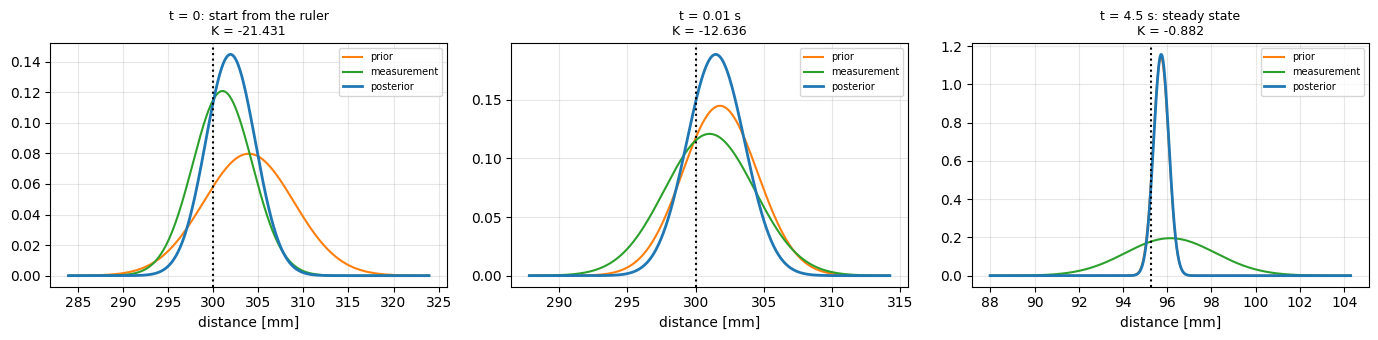

mean NIS = 0.37 (ideal 1);  share above the 95 % chi2 limit = 0.8 % (ideal 5 %)
gate: 0.00 % of the in-range readings rejected by the 3-sigma test; re-syncs per run: mean 0.00, max 0
deliberately wrong start 0 m, true 300 mm -> final error: pure 3-sigma gate -312 mm, gate with re-sync +0.2 mm


In [5]:
k = int(np.flatnonzero((z > 1) & (tt > 1.0))[0])
print(f'drop-out at t = {tt[k]:.2f} s: sensor reads {z[k]:.2f} m; innovation = {abs(f_plain["nu"][k]/np.sqrt(f_plain["S"][k])):.0f} sigma')
print(f'estimate jump without gate: {1e3*R_WHEEL*abs(f_plain["x"][k]-f_plain["xb"][k]):.0f} mm, with gate: {1e3*R_WHEEL*abs(f_gate["x"][k]-f_gate["xb"][k]):.1f} mm')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, kk, ttl in zip(ax, [0, 1, 450], ['t = 0: start from the ruler', 't = 0.01 s', 't = 4.5 s: steady state']):
    o = f_gate; m_pr, s_pr, m_po, s_po = H*o['xb'][kk], R_WHEEL*np.sqrt(o['Pb'][kk]), H*o['x'][kk], R_WHEEL*np.sqrt(o['P'][kk])
    zk, sk = o['z'][kk], np.sqrt(o['R'][kk])                     # calibrated reading and its std
    xs = np.linspace(min(m_pr-4*s_pr, zk-4*sk), max(m_pr+4*s_pr, zk+4*sk), 600)
    a.plot(1e3*xs, norm.pdf(xs, m_pr, s_pr)/1e3, 'tab:orange', label='prior'); a.plot(1e3*xs, norm.pdf(xs, zk, sk)/1e3, 'tab:green', label='measurement')
    a.plot(1e3*xs, norm.pdf(xs, m_po, s_po)/1e3, 'tab:blue', lw=2, label='posterior'); a.axvline(1e3*d_true[kk], color='k', ls=':')
    a.set_title(ttl + f'\nK = {o["K"][kk]:.3f}', fontsize=9); a.set_xlabel('distance [mm]'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# consistency: normalised innovation squared over many runs (drop-outs excluded), expected mean 1
# and how often the gate rejects a reading that is in range (3-sigma test) or re-syncs
nis, n_inrange, n_3s, n_resync = [], 0, 0, []
for s in range(40):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE); keep = ~o['skip'] & (sm['t'] > 1)
    nis.append((o['nu']**2 / o['S'])[keep])
    inrange = (sm['z'] < M_RAW_MAX) & ~o['rej_range']
    n_inrange += inrange.sum(); n_3s += o['rej_3s'].sum(); n_resync.append(o['resync'].sum())
nis = np.concatenate(nis)
print(f'mean NIS = {nis.mean():.2f} (ideal 1);  share above the 95 % chi2 limit = {100*(nis > chi2.ppf(.95, 1)).mean():.1f} % (ideal 5 %)')
print(f'gate: {100*n_3s/n_inrange:.2f} % of the in-range readings rejected by the 3-sigma test; '
      f're-syncs per run: mean {np.mean(n_resync):.2f}, max {np.max(n_resync)}')

# DELIBERATELY WRONG initial estimate (ValueOut1 left at 0), to demonstrate the re-sync:
# a pure 3-sigma gate never accepts a measurement again
def plain_3sigma_gate(m, w, x0):
    x, P = x0, P0
    for k in range(len(m)):
        zk = calibrate(m[k]); nu = zk - H * x; S = H * P * H + R_of_m(m[k])
        if SHARP_B < m[k] < M_RAW_MAX and D_MIN <= zk <= D_MAX and nu**2 <= GATE * S:
            K = P * H / S; x += K * nu; P = (1 - K * H) * P
        x += B * w[k]; P += Q_w(w[k])
    return H * x
bad = 0.0 / -R_WHEEL + 1e-9
print(f'deliberately wrong start 0 m, true {1e3*d_true[0]:.0f} mm -> final error: pure 3-sigma gate {1e3*(plain_3sigma_gate(z, wm, bad) - d_true[-1]):+.0f} mm, '
      f'gate with re-sync {1e3*(H*lkf(z, wm, Q_w, bad, P0, gate=GATE)["x"][-1] - d_true[-1]):+.1f} mm')

## 4. Tuning check and comparison
RMSE after the start-up transient ($t>1$ s) over 100 simulated runs, and the sensitivity to scaling $Q$ and $R$. Starting outside the sensor range (e.g. 0.45 m) means prediction only until the wall comes into range, so the error of the start estimate and the drift of the wheel-speed error stay uncorrected until then (last line below): the filter can only correct what the sensor can see.

                                        median RMSE [mm]  95th pct [mm]
sensor, calibrated (drop-outs removed)               1.7            3.0
prediction only                                      9.2           17.0
LKF (no gate)                                        1.6            2.9
LKF + gate                                           1.6            2.9


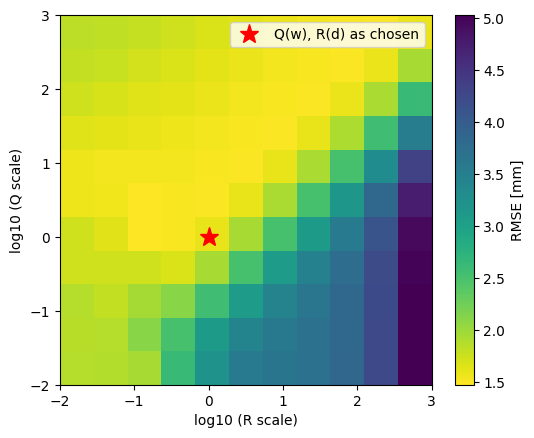

best on grid: Q x 1, R x 0.1 -> 1.5 mm;  data values (x1, x1): 1.6 mm


LKF + gate, median RMSE: start at 0.30 m 1.6 mm, start at 0.45 m (outside the sensor range) 2.9 mm


In [6]:
res = {k: [] for k in ['sensor, calibrated (drop-outs removed)', 'prediction only', 'LKF (no gate)', 'LKF + gate']}
for s in range(100):
    sm = simulate(s); m = sm['t'] > 1; ok = sm['z'] < M_RAW_MAX; e = lambda est: np.sqrt(np.mean((est - sm['d'])[m]**2))
    res['sensor, calibrated (drop-outs removed)'].append(np.sqrt(np.mean((calibrate(sm['z']) - sm['d'])[m & ok]**2)))
    res['prediction only'].append(e(H * (sm['x0'] + B * np.concatenate([[0], np.cumsum(sm['w'][:-1])]))))
    res['LKF (no gate)'].append(e(H * lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0)['x'])); res['LKF + gate'].append(e(H * lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE)['x']))
print(pd.DataFrame({k: [1e3*np.median(v), 1e3*np.percentile(v, 95)] for k, v in res.items()}, index=['median RMSE [mm]', '95th pct [mm]']).T.round(1).to_string())

def rmse_scaled(s, qm, rm):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], lambda w: qm * Q_w(w), sm['x0'], P0, gate=GATE, r_scale=rm)
    return np.sqrt(np.mean((H * o['x'] - sm['d'])[sm['t'] > 1]**2))
sc = np.logspace(-2, 3, 11); grid = np.zeros((len(sc), len(sc)))
for i, qm in enumerate(sc):
    for j, rm in enumerate(sc):
        grid[i, j] = np.mean([rmse_scaled(s, qm, rm) for s in range(8)])
plt.figure(figsize=(6, 4.8)); plt.imshow(1e3*grid, origin='lower', extent=[-2, 3, -2, 3], cmap='viridis_r', aspect='auto'); plt.plot(0, 0, 'r*', ms=14, label='Q(w), R(d) as chosen')
plt.colorbar(label='RMSE [mm]'); plt.xlabel('log10 (R scale)'); plt.ylabel('log10 (Q scale)'); plt.legend(); plt.grid(False); plt.show()
i, j = np.unravel_index(grid.argmin(), grid.shape)
print(f'best on grid: Q x {sc[i]:.2g}, R x {sc[j]:.2g} -> {1e3*grid[i,j]:.1f} mm;  data values (x1, x1): {1e3*grid[5,5]:.1f} mm')

# Starting outside the sensor range: same runs, but from 0.45 m
def rmse_start(d0):
    r = []
    for s in range(100):
        sm = simulate(s, d0=d0); o = lkf(sm['z'], sm['w'], Q_w, sm['x0'], P0, gate=GATE)
        r.append(np.sqrt(np.mean((H * o['x'] - sm['d'])[sm['t'] > 1]**2)))
    return 1e3 * np.median(r)
print(f'LKF + gate, median RMSE: start at 0.30 m {rmse_start(0.30):.1f} mm, start at 0.45 m (outside the sensor range) {rmse_start(0.45):.1f} mm')

### 5.0 Leave-one-run-out: the honest check of the calibration

For each drive: fit the calibration on the S points and the standstill points of the **other two** drives, replay the held-out drive, and compare the end with the tape. The S-only calibration is shown for comparison.

In [7]:
rows = []
for r in WRUNS:
    train = cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]
    sel_start, _ = standstill(r)
    for label, c in [('S + other two W runs', fit_cal(train)), ('S only', CAL_S)]:
        use_cal(c)
        o, met, _ = w_metrics(r, Q_w)
        rows.append({'held-out run': r['name'], 'calibration': label,
                     'filter end vs tape [mm]': met['end_err'],
                     'sensor start vs tape [mm]': 1e3 * (calibrate(r['m'][sel_start]).mean() - r['d_start']),
                     'NIS driving': met['nis_drive'], 'drift [mm]': met['drift'],
                     '3-sigma rej. (driving/all)': f"{met['rej_3s_drive']}/{met['rej_3s']}", 're-syncs': met['resync']})
use_cal(CAL_ALL)                                                           # back to the final calibration
lor = pd.DataFrame(rows)
print(lor.round(2).to_string(index=False))
for label in ['S + other two W runs', 'S only']:
    e = lor[lor.calibration == label]['filter end vs tape [mm]']
    print(f'{label:22s}: end error rms {np.sqrt(np.mean(e**2)):.1f} mm, mean {e.mean():+.1f} mm')

     held-out run          calibration  filter end vs tape [mm]  sensor start vs tape [mm]  NIS driving  drift [mm] 3-sigma rej. (driving/all)  re-syncs
W1_start300_end44 S + other two W runs                     3.02                      -2.11         1.12        1.05                     10/318         0
W1_start300_end44               S only                     7.45                      -8.22         1.67        2.22                     27/334         0
W2_start300_end45 S + other two W runs                     0.59                      -5.82         0.94        0.32                        0/0         0
W2_start300_end45               S only                     5.60                     -11.00         1.18        1.50                        2/2         0
W3_start300_end42 S + other two W runs                     5.64                      -5.95         0.71        0.41                        1/5         0
W3_start300_end42               S only                     9.47                   

### 5.1 Choice of $\mathbf Q$

Compared on the same drives (with $R(d)$, $\sigma_\text{cal}$ = 2 mm): the constant A2 $\mathbf Q$, $\mathbf Q\times10$, and $\mathbf Q(\omega)$ with $k$ from two fits:

* $k$ from the **odometry end errors** (−1.6/−5.9/−9.3 mm vs tape): the $k$ for which the accumulated variance $\sum(k\,\omega\,\Delta t)^2$ matches the mean squared end error;
* $k$ from **consistency**: mean NIS ≈ 1 while driving (scan below).

In [8]:
# k from the odometry end errors (white per-step noise k*|w| that reproduces the end-error rms)
num, den, qs = [], [], []
for r in WRUNS:
    i = np.flatnonzero(np.abs(r['w']) > 0); i0, i1 = i[0], i[-1]
    err = R_WHEEL * DT * r['w'].sum() - (r['d_start'] - r['d_end'])
    num.append((err / R_WHEEL)**2); den.append(np.sum((r['w'][i0:i1 + 1] * DT)**2)); qs.append((i1 - i0 + 1) * (SIGMA_OMEGA * DT)**2)
K_END = np.sqrt(max((np.mean(num) - np.mean(qs)) / np.mean(den), 0))
print(f'odometry end errors {", ".join(f"{1e3*R_WHEEL*np.sqrt(v):.1f}" for v in num)} mm -> k from end errors = {K_END:.2f}\n')

print('k scan, NIS / mean innovation / 3-sigma rejections while driving, per run:')
for kk in [0.05, 0.10, 0.15, 0.20, K_END]:
    ms = [w_metrics(r, lambda w, kk=kk: DT**2 * (SIGMA_OMEGA**2 + (kk * w)**2))[1] for r in WRUNS]
    print(f'  k = {kk:.2f}: NIS {" ".join(f"{m["nis_drive"]:.2f}" for m in ms)} (mean {np.mean([m["nis_drive"] for m in ms]):.2f}),'
          f' drift {" ".join(f"{m["drift"]:+.1f}" for m in ms)} mm, rejections {" ".join(str(m["rej_3s_drive"]) for m in ms)}')

variants = {'A2 Q (constant)': Q, 'A2 Q x 10': 10 * Q,
            f'Q(w), k = {K_END:.2f} (end errors)': lambda w: DT**2 * (SIGMA_OMEGA**2 + (K_END * w)**2),
            'Q(w), k = 0.10 (before the refit)': lambda w: DT**2 * (SIGMA_OMEGA**2 + (0.10 * w)**2),
            f'Q(w), k = {K_SLIP:.2f} (chosen)': Q_w}
rows = []
for name, qv in variants.items():
    ms = [w_metrics(r, qv)[1] for r in WRUNS]
    rows.append({'Q': name, 'end error [mm]': ' '.join(f'{m["end_err"]:+.1f}' for m in ms),
                 'RMS vs ref [mm]': np.mean([m['rms_ref'] for m in ms]), 'NIS driving': np.mean([m['nis_drive'] for m in ms]),
                 'drift [mm]': np.mean([m['drift'] for m in ms]), '3-sigma rej. (driving/all)': f"{sum(m['rej_3s_drive'] for m in ms)}/{sum(m['rej_3s'] for m in ms)}",
                 're-syncs': sum(m['resync'] for m in ms)})
print(); print(pd.DataFrame(rows).round(2).to_string(index=False))

odometry end errors 1.6, 5.9, 9.3 mm -> k from end errors = 0.28

k scan, NIS / mean innovation / 3-sigma rejections while driving, per run:
  k = 0.05: NIS 1.17 0.90 0.71 (mean 0.93), drift +0.9 +0.1 +0.1 mm, rejections 8 0 1
  k = 0.10: NIS 0.89 0.78 0.67 (mean 0.78), drift +0.6 +0.1 +0.1 mm, rejections 7 0 1
  k = 0.15: NIS 0.84 0.72 0.65 (mean 0.73), drift +0.5 +0.1 +0.1 mm, rejections 4 0 1
  k = 0.20: NIS 0.79 0.68 0.63 (mean 0.70), drift +0.4 +0.1 +0.1 mm, rejections 3 0 1
  k = 0.28: NIS 0.70 0.65 0.60 (mean 0.65), drift +0.3 +0.1 +0.1 mm, rejections 3 0 1


                                Q end error [mm]  RMS vs ref [mm]  NIS driving  drift [mm] 3-sigma rej. (driving/all)  re-syncs
                  A2 Q (constant) +2.3 +0.4 +4.4             3.88         1.06        0.59                     15/327         0
                        A2 Q x 10 +2.3 +0.4 +4.4             3.90         0.77        0.23                      6/324         0
      Q(w), k = 0.28 (end errors) +2.3 +0.4 +4.4             3.87         0.65        0.16                      4/316         0
Q(w), k = 0.10 (before the refit) +2.3 +0.4 +4.4             3.88         0.78        0.27                      8/320         0
          Q(w), k = 0.05 (chosen) +2.3 +0.4 +4.4             3.88         0.93        0.40                      9/321         0


### 5.2 Constant $R$ vs $R(d)$, and $\sigma_\text{cal}$

Same drives, $\mathbf Q(\omega)$. The constant $R$ is $R(d)$ at mid-range (175 mm).

In [9]:
r_with = lambda s: (lambda m: sigma_d(m)**2 + s**2)
R_MID = R_of_m(np.interp(0.175, d_grid, m_grid))
rvariants = {'R(d), sigma_cal 1 mm': r_with(0.001), 'R(d), sigma_cal 1.5 mm': r_with(0.0015),
             'R(d), sigma_cal 2 mm (chosen)': None, 'R(d), sigma_cal 3 mm': r_with(0.003), 'R(d), sigma_cal 5 mm': r_with(0.005),
             f'constant R = ({1e3*np.sqrt(R_MID):.1f} mm)^2': lambda m: R_MID}
rows = []
for name, rf in rvariants.items():
    ms = [w_metrics(r, Q_w, r_func=rf)[1] for r in WRUNS]
    rows.append({'R': name, 'end error [mm]': ' '.join(f'{m["end_err"]:+.1f}' for m in ms),
                 'RMS vs ref [mm]': np.mean([m['rms_ref'] for m in ms]), 'NIS driving': np.mean([m['nis_drive'] for m in ms]),
                 'drift [mm]': np.mean([m['drift'] for m in ms]), '3-sigma rej. (driving/all)': f"{sum(m['rej_3s_drive'] for m in ms)}/{sum(m['rej_3s'] for m in ms)}",
                 're-syncs': sum(m['resync'] for m in ms)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

# W1 stands still before the drive with readings jumping between two levels: that is where most rejections are
r = WRUNS[0]; t0 = r['t'][r['drive']][0]; seg = r['m'][(r['t'] > 0.5) & (r['t'] < t0 - 0.1)]
print(f"\n{r['name']} before the drive: calibrated std {1e3*calibrate(seg).std():.1f} mm vs sqrt(R) {1e3*np.sqrt(R_of_m(np.median(seg))):.1f} mm; "
      f"ADC counts {{int(k): int(v) for k, v in zip(*np.unique(np.round(SHARP_A/(seg-SHARP_B)).astype(int), return_counts=True))}}")

                            R end error [mm]  RMS vs ref [mm]  NIS driving  drift [mm] 3-sigma rej. (driving/all)  re-syncs
         R(d), sigma_cal 1 mm +2.3 +0.4 +4.4             3.91         1.45        0.37                     30/375         0
       R(d), sigma_cal 1.5 mm +2.3 +0.4 +4.4             3.89         1.11        0.35                     20/343         0
R(d), sigma_cal 2 mm (chosen) +2.3 +0.4 +4.4             3.88         0.93        0.40                      9/321         0
         R(d), sigma_cal 3 mm +2.3 +0.5 +4.4             3.59         0.60        0.44                      3/108         0
         R(d), sigma_cal 5 mm +2.3 +0.5 +4.4             3.47         0.29        0.61                        0/1         0
      constant R = (2.3 mm)^2 +2.3 +0.4 +4.4             4.02         0.97        0.23                     23/441         1

W1_start300_end44 before the drive: calibrated std 5.7 mm vs sqrt(R) 3.2 mm; ADC counts {int(k): int(v) for k, v in zip(*np.unique(

### 7.1 Electrical equation and datasheet comparison

With $L$ neglected, $V = R_a I + K_e n\,\omega$ holds at every sample, so $R_a$ and $K_e$ follow from a regression of $V$ on $[I,\ \omega]$ (no intercept). The step transients give the current information (spikes of 0.1–0.2 A); in steady state the current is only 0.01–0.03 A.

Then $J$ and $c$ follow from the fitted $\tau$ and $g$: $c + K_tK_e/R_a = K_t/(R_a\,n\,g)$ and $J = \tau\,(c + K_tK_e/R_a)$, once with the datasheet $K_t, K_e, R_a$ and once with the fitted ones ($K_t = K_e$ in SI units).

In [10]:
ELEC = {}
for wh in 'AB':
    X = np.column_stack([M1['I' + wh], M1['w' + wh]])
    reg = LinearRegression(fit_intercept=False).fit(X, M1['V' + wh])
    ELEC[wh] = dict(Ra=reg.coef_[0], Ke=reg.coef_[1] / N_GEAR, r2=reg.score(X, M1['V' + wh]))
elec = pd.DataFrame(ELEC).T
print('V = Ra I + Ke n w  (all M1 samples):'); print(elec.round(5).to_string())
print(f'datasheet: Ra = {RA_DS} ohm, Ke = Kt = {KE_DS} V s/rad')

def j_and_c(tau, gain, Kt, Ke, Ra):
    D = Kt / (Ra * N_GEAR * gain)              # c + Kt Ke / Ra  [N m s/rad], motor side
    return tau * D, D - Kt * Ke / Ra           # J [kg m^2], c [N m s/rad]

rows = []
for wh in 'AB':
    tau, g = MOTOR[wh]['tau'], MOTOR[wh]['gain']
    for label, (Kt, Ke, Ra) in [('datasheet Kt, Ke, Ra', (KT_DS, KE_DS, RA_DS)), ('fitted Ke (= Kt), Ra', (ELEC[wh]['Ke'], ELEC[wh]['Ke'], ELEC[wh]['Ra']))]:
        J, c = j_and_c(tau, g, Kt, Ke, Ra)
        rows.append({'wheel': wh, 'electrical constants': label, 'J [kg m^2]': J, 'J / Jm': J / JM_DS, 'c [N m s/rad]': c,
                     'c / (Kt Ke / Ra)': c / (Kt * Ke / Ra)})
print('\nMechanical constants from the fitted tau and gain (motor side):')
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f'{v:.3g}'))
print(f'\ndatasheet prediction (J = Jm, c = 0): tau = {1e3*JM_DS*RA_DS/(KT_DS*KE_DS):.1f} ms, gain = {1/(KE_DS*N_GEAR):.3f} rad/s/V '
      f'(measured: {1e3*MOTOR["A"]["tau"]:.1f} / {1e3*MOTOR["B"]["tau"]:.1f} ms, {MOTOR["A"]["gain"]:.3f} / {MOTOR["B"]["gain"]:.3f} rad/s/V)')

V = Ra I + Ke n w  (all M1 samples):
         Ra       Ke       r2
A  14.85070  0.01597  0.99701
B  16.28099  0.01587  0.99718
datasheet: Ra = 8.77 ohm, Ke = Kt = 0.0145 V s/rad

Mechanical constants from the fitted tau and gain (motor side):
wheel electrical constants  J [kg m^2]  J / Jm  c [N m s/rad]  c / (Kt Ke / Ra)
    A datasheet Kt, Ke, Ra    5.01e-07    1.86       3.54e-06             0.148
    A fitted Ke (= Kt), Ra    3.26e-07    1.21        7.2e-07            0.0419
    B datasheet Kt, Ke, Ra    4.99e-07    1.85       3.75e-06             0.156
    B fitted Ke (= Kt), Ra    2.94e-07    1.09       8.71e-07            0.0563

datasheet prediction (J = Jm, c = 0): tau = 11.3 ms, gain = 2.425 rad/s/V (measured: 18.2 / 18.0 ms, 2.113 / 2.097 rad/s/V)


**Reading the numbers.** The measured motor is slower (τ ≈ 18 ms vs 11 ms) and has a lower gain (≈ 2.1 vs 2.4 rad/s/V) than the datasheet predicts with $J = J_m$, $c = 0$. With the **datasheet** electrical constants this is explained by $J \approx 1.9\,J_m$ (gearbox and wheel inertia) and a viscous friction $c$ of about 15 % of the electrical damping $K_tK_e/R_a$. The electrical regression, however, gives $K_e \approx 0.016$ V s/rad (+10 %) and $R_a \approx 15$–16 Ω (+75 %); with **those** constants $J \approx 1.1$–$1.2\,J_m$ and $c$ is only 4–6 % of the electrical damping. The two cannot be separated with this data: $R_a$ depends on the scale of the current measurement and includes the H-bridge and wiring, and the voltage is the commanded one, not the measured terminal voltage. For the filter only $\alpha$ and $\beta$ matter, and those are measured directly.

The static fit also shows an offset: $|\omega| \approx 2.17\,(|V| - 0.18\ \text{V})$, i.e. a small Coulomb (dry) friction, which the linear model $\omega_{k+1} = \alpha\omega_k + \beta V_k$ absorbs into a slightly lower gain (2.11 instead of 2.17 rad/s/V).

### 3-state filter: per-channel NIS and missing-encoder detail (former 7.4)

In [11]:
rows3, KF3_RUNS = [], {}
for j, r in enumerate(WRUNS):
    use_cal(fit_cal(cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]))
    a_j, b_j, q_j = floor_fit([FLOOR[i] for i in range(len(FLOOR)) if i != j])
    df = load_log(DATA_A3 / (r['name'] + '.csv'), firmware='identification_a3'); drv = r['drive']
    o1, met1, ref = w_metrics(r, Q_w)
    for enc_name, s_enc in [('quantisation 0.10', SIG_ENC_Q), ('A2 0.18', SIGMA_OMEGA)]:
        o3 = kf3(df.front.values, df.VA.values, df.VB.values, df.wA.values, df.wB.values, r['d_start'] / -R_WHEEL, a_j, b_j, q_j, s_enc**2)
        d3 = H * o3['x'][:, 0]
        if enc_name.startswith('quant'):
            KF3_RUNS[r['name']] = dict(o3=o3, o1=o1, df=df, a=a_j, b=b_j)
        rows3.append({'run': r['name'][:2], 'encoder R': enc_name,
                      'end err 3-state [mm]': 1e3 * (d3[-1] - r['d_end']), 'end err mandatory [mm]': met1['end_err'],
                      'RMS vs ref 3-state [mm]': 1e3 * np.sqrt(np.mean((d3 - ref)**2)), 'RMS vs ref mandatory [mm]': met1['rms_ref'],
                      'NIS 3-D driving (3)': np.nanmean(o3['nis3'][drv]), 'NIS d': np.nanmean(o3['nis_ch'][drv, 0]),
                      'NIS wA': np.nanmean(o3['nis_ch'][drv, 1]), 'NIS wB': np.nanmean(o3['nis_ch'][drv, 2]),
                      'NIS mandatory (1)': met1['nis_drive'],
                      'w_A est - encoder RMS [rad/s]': np.sqrt(np.mean((o3['x'][drv, 1] - df.wA.values[drv])**2)),
                      'gate rej. 3-state / mand.': f"{o3['rej_3s'][drv].sum()} / {met1['rej_3s_drive']}"})
use_cal(CAL_ALL)
t3s = pd.DataFrame(rows3)
pd.set_option('display.width', 250)
print(t3s.round(2).to_string(index=False))
print('\nmeans per encoder R:')
print(t3s.drop(columns=['run', 'gate rej. 3-state / mand.']).groupby('encoder R').mean().round(2).T.to_string())

run         encoder R  end err 3-state [mm]  end err mandatory [mm]  RMS vs ref 3-state [mm]  RMS vs ref mandatory [mm]  NIS 3-D driving (3)  NIS d  NIS wA  NIS wB  NIS mandatory (1)  w_A est - encoder RMS [rad/s] gate rej. 3-state / mand.
 W1 quantisation 0.10                  3.02                    3.02                     3.88                       3.90                 3.90   1.37    1.36    1.27               1.12                           0.05                   14 / 10
 W1           A2 0.18                  3.02                    3.02                     3.89                       3.90                 3.01   1.26    0.95    0.88               1.12                           0.11                   14 / 10
 W2 quantisation 0.10                  0.59                    0.59                     4.69                       4.68                 3.08   1.08    1.12    0.87               0.94                           0.05                     1 / 0
 W2           A2 0.18                  0

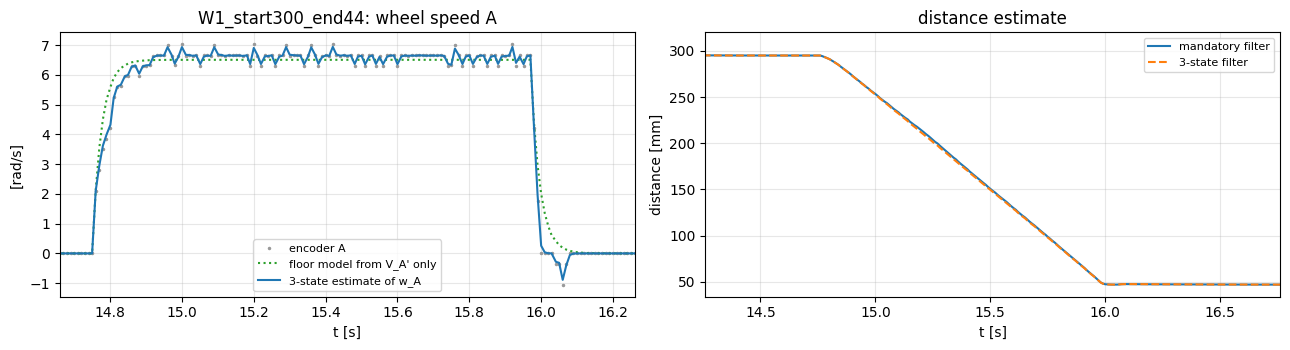

Encoder A missing for 0.3 s mid-drive (distance sensor still working):
  W1: max distance change vs the normal replay: mandatory 30.3 mm, 3-state 0.9 mm; w_A in the gap: 3-state estimate vs true encoder RMS 0.25 rad/s


  W2: max distance change vs the normal replay: mandatory 31.4 mm, 3-state 0.8 mm; w_A in the gap: 3-state estimate vs true encoder RMS 0.32 rad/s
  W3: max distance change vs the normal replay: mandatory 27.2 mm, 3-state 0.2 mm; w_A in the gap: 3-state estimate vs true encoder RMS 0.19 rad/s


In [12]:
# One drive in detail (quantisation encoder R): speed estimate and distance of both filters
name = WRUNS[0]['name']; k3 = KF3_RUNS[name]; df = k3['df']; r = WRUNS[0]
t0 = r['t'][r['drive']][0]
w_model = sim_ab(uprime(df.VA.values), k3['a'], k3['b'])                  # floor model from the voltage only
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(df.t, df.wA, '.', ms=3, color='0.6', label='encoder A')
ax[0].plot(df.t, w_model, ':', color='tab:green', label="floor model from V_A' only")
ax[0].plot(df.t, k3['o3']['x'][:, 1], color='tab:blue', label='3-state estimate of w_A')
ax[0].set(xlim=(t0 - 0.1, t0 + 1.5), xlabel='t [s]', ylabel='[rad/s]', title=f'{name}: wheel speed A'); ax[0].legend(fontsize=8)
ax[1].plot(df.t, 1e3 * H * k3['o1']['x'], label='mandatory filter')
ax[1].plot(df.t, 1e3 * H * k3['o3']['x'][:, 0], '--', label='3-state filter')
ax[1].set(xlim=(t0 - 0.5, t0 + 2), xlabel='t [s]', ylabel='distance [mm]', title='distance estimate'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Missing encoder: encoder A gives no reading for 0.3 s in the middle of the drive (e.g. a loose connector).
# The mandatory filter has no choice but to use what the encoder reads (here 0); the 3-state filter predicts w_A from V_A'.
print('Encoder A missing for 0.3 s mid-drive (distance sensor still working):')
for r in WRUNS:
    k3 = KF3_RUNS[r['name']]; df = k3['df']; drv = np.arange(len(df))[r['drive']]
    gap = np.zeros(len(df), bool); gap[drv[40]:drv[70]] = True
    wA_bad = np.where(gap, 0.0, df.wA.values)
    use_cal(fit_cal(cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]))
    o1 = lkf(df.front.values, (wA_bad + df.wB.values) / 2, Q_w, r['d_start'] / -R_WHEEL, P0, gate=GATE)
    o3 = kf3(df.front.values, df.VA.values, df.VB.values, wA_bad, df.wB.values, r['d_start'] / -R_WHEEL, k3['a'], k3['b'],
             QW3S, SIG_ENC_Q**2, drop_A=gap)
    d_ok1, d_ok3 = H * k3['o1']['x'], H * k3['o3']['x'][:, 0]
    print(f"  {r['name'][:2]}: max distance change vs the normal replay: mandatory {1e3*np.max(np.abs(H*o1['x'] - d_ok1)):.1f} mm, "
          f"3-state {1e3*np.max(np.abs(H*o3['x'][:, 0] - d_ok3)):.1f} mm; w_A in the gap: 3-state estimate vs true encoder RMS "
          f"{np.sqrt(np.mean((o3['x'][gap, 1] - df.wA.values[gap])**2)):.2f} rad/s")
use_cal(CAL_ALL)

### IMU filter: per-channel NIS while driving (driving sigma_a, held-out calibration)

In [13]:
for r in WRUNS:
    use_cal(fit_cal(cal_pts[~cal_pts.source.str.startswith(r['name'][:2])]))
    df = load_log(DATA_A3 / (r['name'] + '.csv'), firmware='identification_a3'); drv = r['drive']
    oi = kf_imu(df.front.values, imu_forward(df), ((df.wA + df.wB) / 2).values, r['d_start'] / -R_WHEEL, SIG_A_DRIVE)
    print(f"{r['name'][:2]}: NIS distance {np.nanmean(oi['nis_ch'][drv, 0]):.2f}, speed {np.nanmean(oi['nis_ch'][drv, 1]):.2f}")
use_cal(CAL_ALL)

W1: NIS distance 3.06, speed 2.47
W2: NIS distance 1.80, speed 3.13


W3: NIS distance 1.19, speed 3.31
